In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


In [3]:

df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")



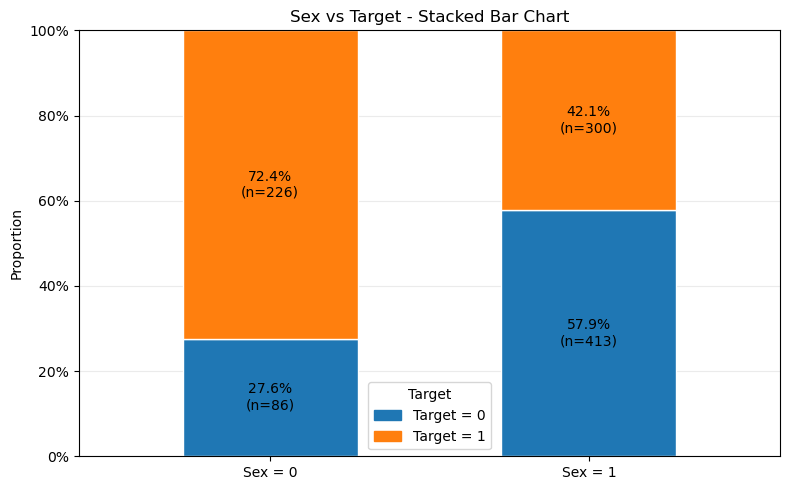

In [4]:

counts = pd.crosstab(df["sex"], df["target"])
counts = counts.reindex(
    index=[0, 1], columns=[0, 1], fill_value=0
)

totals = counts.sum(axis=1)
proportions = counts.div(totals, axis=0)

colors = ["tab:blue", "tab:orange"]

fig, ax = plt.subplots(figsize=(8, 5))

bar_width = 0.55

for x, sex in enumerate([0, 1]):

    bottom = 0

    for target in [0, 1]:

        proportion = proportions.loc[sex, target]
        count = counts.loc[sex, target]

        rectangle = Rectangle(
            (x - bar_width / 2, bottom),
            bar_width,
            proportion,
            facecolor=colors[target],
            edgecolor="white"
        )

        ax.add_patch(rectangle)

        ax.text(
            x,
            bottom + proportion / 2,
            f"{proportion:.1%}\n(n={count})",
            ha="center",
            va="center"
        )

        bottom += proportion

ax.set_xlim(-0.6, 1.6)
ax.set_ylim(0, 1)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Sex = 0", "Sex = 1"])

ax.set_ylabel("Proportion")
ax.set_title("Sex vs Target - Stacked Bar Chart")

ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
ax.set_yticklabels(
    ["0%", "20%", "40%", "60%", "80%", "100%"]
)

legend_patches = [
    Rectangle((0, 0), 1, 1, color=colors[0], label="Target = 0"),
    Rectangle((0, 0), 1, 1, color=colors[1], label="Target = 1")
]

ax.legend(handles=legend_patches, title="Target")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()